# Removing spoken punctuation from AfriSpeech: effect on WER

AfriSpeech speakers were asked to **say punctuation out loud** ("... severe disease full stop"). The reference
transcripts contain the punctuation *symbols* (".", ","), which Whisper's normaliser deletes, but Whisper transcribes
the spoken *words* ("full stop", "comma"). Without correction, every spoken punctuation mark is counted as an
inserted word, so WER would partly measure whether the speaker followed the punctuation instruction rather than how
well their speech was recognised.

The normaliser therefore removes a fixed list of punctuation phrases from AfriSpeech references and hypotheses
(whole-word matches only, longest phrase first). This notebook compares scoring **with** the removal against
scoring **without** it, on the same Whisper-base transcripts:

1. Overall effect: mean WER, corpus WER, and substitutions / deletions / insertions
2. Per-recording effect: how many recordings changed, in which direction, and whether it is consistent
3. Which terms were removed, and whether any were removed from a reference (i.e. were probably real words)
4. Recordings that got worse, and the largest changes
5. Spoken punctuation Whisper *mis-recognised* (e.g. "comma" → "coma"), which the removal cannot catch

## 0. Configuration

In [1]:
from pathlib import Path

RESULTS_ROOT = Path("../results/asr/")

# The same Whisper-base transcripts scored twice: punctuation words kept vs removed
KEPT_SCORED_PATH = RESULTS_ROOT / "runs/analysis_base_long/scored_punc_kept.csv"
REMOVED_SCORED_PATH = RESULTS_ROOT / "runs/analysis_base_long/scored_punc_removed.csv"
MANIFEST_PATH = RESULTS_ROOT / "runs/analysis_base_long/manifest_snapshot.csv"

DATASET = "afrispeech"
ACCENT_COL = "accent_group"
DOMAIN_COL = "domain"

# Keep this list the same as AFRISPEECH_PUNCTUATION_TERMS in normalize.py
PUNCTUATION_TERMS = [
    "full stop", "question mark", "exclamation mark", "open bracket", "close bracket",
    "open parenthesis", "close parenthesis", "comma", "semi colon", "semicolon", "colon",
    "slash", "hyphen", "dash", "period", "query",
]

# Terms that are NOT in the list, tested in section 7 as possible additions
CANDIDATE_TERMS = ["next line", "new line"]

# Words that look like mis-recognised spoken punctuation (checked in section 7). Edit after looking at the
# "most common inserted words" table.
NEAR_MISS_WORDS = ["coma", "koma", "stop", "stock", "stall", "store", "stone", "fustob", "full"]
# Multi-word versions that look like a mis-heard "full stop" (counted in hypotheses and references)
NEAR_MISS_PHRASES = ["full stock", "full stall", "full store", "full stone", "for stop", "to stop", "just stop", "1st up"]

# Recordings with WER above this in either version are left out (hallucination loops); None keeps everything
WER_CAP = 2.0

In [2]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jiwer
from scipy import stats
from IPython.display import display

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 140)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

INK, GREY, BLUE, ORANGE, AQUA = "#33322e", "#b5b4ad", "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e3e2dc", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8980", "axes.labelcolor": INK, "xtick.color": "#5c5b55",
    "ytick.color": "#5c5b55", "font.size": 10, "legend.frameon": False,
})
REPORT_STYLE = {"font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
                "legend.fontsize": 7.5}

def save_report_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    print(f"Saved {FIG_DIR / name}.pdf / .png")

## 1. Load and pair the two scorings

In [3]:
cols = ["sample_id", "dataset", "reference_norm", "hypothesis_norm", "wer", "substitutions", "deletions",
        "insertions", "hits", "n_reference_words", "scoring_status"]
kept = pd.read_csv(KEPT_SCORED_PATH)[cols]
removed = pd.read_csv(REMOVED_SCORED_PATH)[cols]
for df in (kept, removed):
    for c in ["reference_norm", "hypothesis_norm"]:
        df[c] = df[c].fillna("").astype(str).str.split().str.join(" ")
    df["errors"] = df["substitutions"] + df["deletions"] + df["insertions"]

both = kept.merge(removed.drop(columns="dataset"), on="sample_id", suffixes=("_kept", "_removed"))
print(f"{len(both)} recordings scored both ways")

# Sanity check: removal should only affect the target dataset
other = both[both["dataset"] != DATASET]
print(f"Other datasets: {len(other)} recordings, WER changed for {(~np.isclose(other['wer_kept'], other['wer_removed'])).sum()}"
      " (should be 0)")

d = both[both["dataset"] == DATASET].copy()
manifest = pd.read_csv(MANIFEST_PATH)
meta = manifest[["sample_id"] + [c for c in [ACCENT_COL, DOMAIN_COL, "reference_transcript"] if c in manifest]]
d = d.merge(meta.rename(columns={ACCENT_COL: "accent", DOMAIN_COL: "domain"}), on="sample_id", how="left")

if WER_CAP is not None:
    too_high = d[(d["wer_kept"] > WER_CAP) | (d["wer_removed"] > WER_CAP)]
    print(f"Leaving out {len(too_high)} recordings with WER > {WER_CAP} in either version: "
          f"{too_high['sample_id'].tolist()}")
    d = d.drop(too_high.index)
print(f"{DATASET}: {len(d)} recordings analysed")
display(d.groupby(["accent", "domain"]).size().unstack(fill_value=0))

580 recordings scored both ways
Other datasets: 407 recordings, WER changed for 0 (should be 0)
Leaving out 2 recordings with WER > 2.0 in either version: ['afrispeech_03bcfda67aaa67be96d4e44acadf3615', 'afrispeech_12db0516db3e30de0d08e6eb0cb42370']
afrispeech: 171 recordings analysed


domain,clinical,general
accent,,
hausa,17,9
kiswahili,17,27
yoruba,45,56


In [4]:
# Re-align every pair with jiwer so individual inserted / substituted words can be inspected later.
# First check that this reproduces the stored counts exactly.
def align(ref, hyp):
    out = jiwer.process_words(ref, hyp)
    r, h = out.references[0], out.hypotheses[0]
    ins, subs, dels = [], [], []
    for chunk in out.alignments[0]:
        if chunk.type == "insert":
            ins += h[chunk.hyp_start_idx:chunk.hyp_end_idx]
        elif chunk.type == "substitute":
            subs += list(zip(r[chunk.ref_start_idx:chunk.ref_end_idx], h[chunk.hyp_start_idx:chunk.hyp_end_idx]))
        elif chunk.type == "delete":
            dels += r[chunk.ref_start_idx:chunk.ref_end_idx]
    return ins, subs, dels

for v in ["kept", "removed"]:
    aligned = [align(r, h) for r, h in zip(d[f"reference_norm_{v}"], d[f"hypothesis_norm_{v}"])]
    d[f"ins_words_{v}"] = [a[0] for a in aligned]
    d[f"sub_pairs_{v}"] = [a[1] for a in aligned]
    d[f"del_words_{v}"] = [a[2] for a in aligned]
    ok = ((d[f"ins_words_{v}"].str.len() == d[f"insertions_{v}"]) &
          (d[f"sub_pairs_{v}"].str.len() == d[f"substitutions_{v}"]) &
          (d[f"del_words_{v}"].str.len() == d[f"deletions_{v}"])).all()
    print(f"jiwer re-alignment matches the stored S/D/I counts ({v}): {ok}")

jiwer re-alignment matches the stored S/D/I counts (kept): True
jiwer re-alignment matches the stored S/D/I counts (removed): True


**Analysis of data used:** 

The same Whisper-base long-form transcripts (580 recordings) were scored twice, once with the spoken-punctuation removal and once without. As a sanity check, none of the 407 SAA recordings changed, so the removal only touches AfriSpeech, as intended.

Two AfriSpeech recordings were left out because their WER is above 2 in both versions (possibily hallucination loops). That leaves **171 AfriSpeech recordings**: Hausa 26, Kiswahili 44 and Yoruba 101, of which 79 are clinical and 92 general. Re-aligning every pair with jiwer reproduced the stored substitution, deletion and insertion counts exactly, so the word-level breakdowns in sections 6–7 are consistent with the scored files.

## 2. Overall effect

* **Mean WER:** average of the per-recording WERs (each recording counts equally).
* **Corpus WER:** total errors / total reference words (each word counts equally; the same as pooled WER).

In [5]:
def totals(v):
    s = d[[f"substitutions_{v}", f"deletions_{v}", f"insertions_{v}", f"hits_{v}", f"n_reference_words_{v}"]].sum()
    s.index = ["substitutions", "deletions", "insertions", "hits", "reference words"]
    s["total errors"] = s[["substitutions", "deletions", "insertions"]].sum()
    s["hypothesis words"] = int(d[f"hypothesis_norm_{v}"].str.split().str.len().sum())
    return s

overall = pd.DataFrame({"punctuation kept": totals("kept"), "punctuation removed": totals("removed")})
overall["change"] = overall["punctuation removed"] - overall["punctuation kept"]
overall["% change"] = overall["change"] / overall["punctuation kept"] * 100

wer = pd.DataFrame({
    "punctuation kept": [d["wer_kept"].mean() * 100, overall.loc["total errors", "punctuation kept"] / overall.loc["reference words", "punctuation kept"] * 100],
    "punctuation removed": [d["wer_removed"].mean() * 100, overall.loc["total errors", "punctuation removed"] / overall.loc["reference words", "punctuation removed"] * 100],
}, index=["mean WER %", "corpus WER %"])
wer["change (pp)"] = wer["punctuation removed"] - wer["punctuation kept"]
display(wer.round(2))
display(overall.round(1))

,punctuation kept,punctuation removed,change (pp)
mean WER %,49.83,46.40,-3.43
corpus WER %,45.86,42.53,-3.33


,punctuation kept,punctuation removed,change,% change
substitutions,784,776,-8,-1.0
deletions,134,139,5,3.7
insertions,584,477,-107,-18.3
hits,2357,2358,1,0.0
reference words,3275,3273,-2,-0.1
total errors,1502,1392,-110,-7.3
hypothesis words,3725,3611,-114,-3.1


Saved figures\punctuation_removal_error_types.pdf / .png


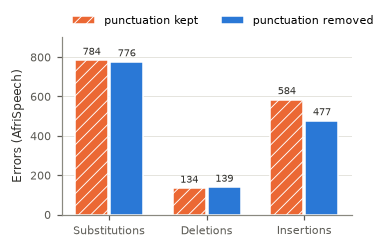

In [19]:
with plt.rc_context({**REPORT_STYLE, "hatch.linewidth": 0.6}):
    fig, ax = plt.subplots(figsize=(3.5, 2.3))
    kinds = ["substitutions", "deletions", "insertions"]
    x = np.arange(len(kinds))
    styles = [
        ("punctuation kept", ORANGE, "///"),   # stripes so it still differs from blue in black-and-white
        ("punctuation removed", BLUE, None),
    ]
    for off, (v, c, hatch) in zip([-0.18, 0.18], styles):
        vals = overall.loc[kinds, v]
        ax.bar(x + off, vals, width=0.34, color=c, label=v, edgecolor="white", linewidth=1, hatch=hatch)
        for xi, val in zip(x + off, vals):
            ax.annotate(f"{int(val)}", (xi, val), xytext=(0, 2), textcoords="offset points", ha="center",
                        va="bottom", fontsize=6.5, color=INK)
    ax.set_xticks(x, ["Substitutions", "Deletions", "Insertions"])
    ax.set_ylabel("Errors (AfriSpeech)")
    ax.set_ylim(0, overall.loc[kinds, ["punctuation kept", "punctuation removed"]].max().max() * 1.15)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
    plt.tight_layout()
    save_report_figure(fig, "punctuation_removal_error_types")
    plt.show()

**Analysis of overall effect:**

Almost the whole improvement comes from **insertions**. That is exactly what is expected since the reference transcripts contain punctuation symbols rather than spoken punctuation words, so every "full stop" or "comma" Whisper wrote had nothing to match and was counted as an extra word.

The small shift from substitutions to deletions happens when a punctuation word had been aligned against a real reference word. Once it is removed, that reference word is left unmatched, so a substitution becomes a deletion. That is why 114 removed words reduced the error count by 110 rather than 114.

## 3. Per-recording effect

In [21]:
d["wer_change"] = d["wer_removed"] - d["wer_kept"]            # negative = removal improved WER
d["changed"] = ~np.isclose(d["wer_kept"], d["wer_removed"])
d["outcome"] = np.select([d["wer_change"] < -1e-12, d["wer_change"] > 1e-12], ["better", "worse"], "same")

counts = d["outcome"].value_counts().reindex(["better", "same", "worse"], fill_value=0).rename("recordings").to_frame()
counts["%"] = counts["recordings"] / len(d) * 100
display(counts.round(1))

ch = d[d["changed"]]
print(f"Of the {len(ch)} recordings that changed, {(ch['outcome'] == 'better').sum()} improved")
print(f"Among changed recordings, WER change: median {ch['wer_change'].median()*100:+.1f} pp, "
      f"range {ch['wer_change'].min()*100:+.1f} to {ch['wer_change'].max()*100:+.1f} pp")

,recordings,%
outcome,,
better,46,26.9
same,123,71.9
worse,2,1.2


Of the 48 recordings that changed, 46 improved
Among changed recordings, WER change: median -10.3 pp, range -40.0 to +2.0 pp


In [8]:
print("By accent and domain:")
def group_summary(col):
    rows = []
    for g, x in d.groupby(col):
        rows.append({col: g, "recordings": len(x), "changed": int(x["changed"].sum()),
                     "% changed": x["changed"].mean() * 100,
                     "mean WER kept %": x["wer_kept"].mean() * 100,
                     "mean WER removed %": x["wer_removed"].mean() * 100,
                     "mean change (pp)": x["wer_change"].mean() * 100,
                     "corpus WER kept %": x["errors_kept"].sum() / x["n_reference_words_kept"].sum() * 100,
                     "corpus WER removed %": x["errors_removed"].sum() / x["n_reference_words_removed"].sum() * 100})
    return pd.DataFrame(rows).set_index(col)
display(group_summary("accent").round(2))
if "domain" in d:
    display(group_summary("domain").round(2))

By accent and domain:


,recordings,changed,% changed,mean WER kept %,mean WER removed %,mean change (pp),corpus WER kept %,corpus WER removed %
accent,,,,,,,,
hausa,26,9,34.62,53.82,49.20,-4.62,49.90,45.16
kiswahili,44,18,40.91,37.04,31.84,-5.21,34.33,29.58
yoruba,101,21,20.79,54.38,52.02,-2.36,50.37,48.10


,recordings,changed,% changed,mean WER kept %,mean WER removed %,mean change (pp),corpus WER kept %,corpus WER removed %
domain,,,,,,,,
clinical,79,20,25.32,54.02,51.10,-2.92,49.75,46.72
general,92,28,30.43,46.24,42.36,-3.88,43.01,39.45


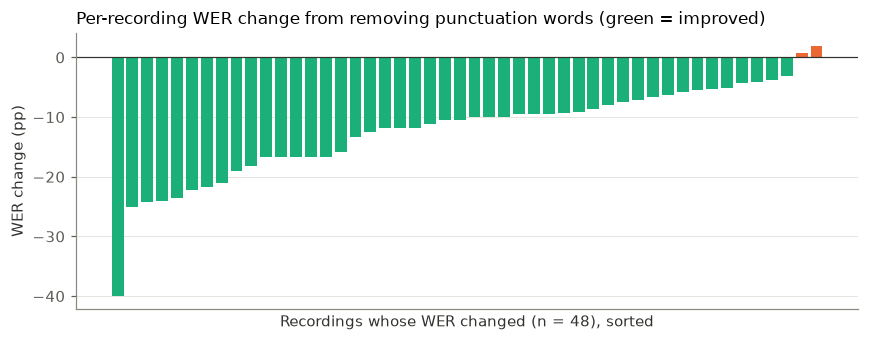

In [9]:
# Per-recording WER change for the recordings that changed
fig, ax = plt.subplots(figsize=(8, 3.2))
vals = ch.sort_values("wer_change")["wer_change"] * 100
ax.bar(np.arange(len(vals)), vals, color=[AQUA if v < 0 else ORANGE for v in vals], width=0.8)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel(f"Recordings whose WER changed (n = {len(vals)}), sorted")
ax.set_ylabel("WER change (pp)")
ax.set_xticks([])
ax.set_title("Per-recording WER change from removing punctuation words (green = improved)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Analysis of per-recording effect:**

* **Most recordings were unaffected:** 123 (72%) had exactly the same WER, because the speaker did not say any punctuation or Whisper did not transcribe it.
* **Of the 48 that changed, 46 improved and 2 got worse**. The median improvement among changed recordings was 10.3 pp.
* **The effect is consistent.** Of the 47 recordings where words were removed only from the hypothesis, 46 improved and none got worse. The remaining one stayed the same: the words re-aligned so that the total error count did not change. The two that got worse are the two cases where a real word was removed from the reference (section 4.1).

The effect differs by accent:

| Accent | Recordings changed | Mean WER change | Corpus WER |
|---|---|---|---|
| Kiswahili | 41% | −5.2 pp | 34.3% → 29.6% |
| Hausa | 35% | −4.6 pp | 49.9% → 45.2% |
| Yoruba | 21% | −2.4 pp | 50.4% → 48.1% |

This is the main reason the correction matters for the study. Without it, part of each accent group's WER would reflect how often its speakers followed the instruction to say punctuation aloud, not how well their speech was recognised. The ordering of the three accents is the same with and without the removal (Kiswahili lowest, then Hausa, then Yoruba), so the correction sharpens the comparison rather than reversing it. The improvement is similar in both domains: −2.9 pp for clinical and −3.9 pp for general.

## 4. Which terms were removed?

Counted by running the same whole-word, longest-first matching as `normalize.py` on the **punctuation-kept**
texts. Terms found in a **reference** are a warning sign: the references contain punctuation symbols, not spoken
punctuation words, so a match there is almost certainly a real word that was removed by mistake.

In [10]:
PHRASES = sorted([p.split() for p in PUNCTUATION_TERMS], key=len, reverse=True)

def find_terms(text, phrases=PHRASES):
    tokens, found, i = text.split(), [], 0
    while i < len(tokens):
        for p in phrases:
            if tokens[i:i + len(p)] == p:
                found.append(" ".join(p)); i += len(p); break
        else:
            i += 1
    return found

d["terms_hyp"] = d["hypothesis_norm_kept"].map(find_terms)
d["terms_ref"] = d["reference_norm_kept"].map(find_terms)

hyp_counts = Counter(t for ts in d["terms_hyp"] for t in ts)
ref_counts = Counter(t for ts in d["terms_ref"] for t in ts)
terms = pd.DataFrame({
    "removed from hypotheses": pd.Series(hyp_counts),
    "recordings (hyp)": pd.Series(Counter(t for ts in d["terms_hyp"] for t in set(ts))),
    "removed from references": pd.Series(ref_counts),
}).reindex(PUNCTUATION_TERMS).fillna(0).astype(int)
terms = terms.sort_values("removed from hypotheses", ascending=False)
display(terms)
n_tokens = sum(len(t.split()) * c for t, c in hyp_counts.items())
print(f"{sum(hyp_counts.values())} terms ({n_tokens} words) removed from hypotheses in "
      f"{(d['terms_hyp'].str.len() > 0).sum()} of {len(d)} recordings; "
      f"{sum(ref_counts.values())} removed from references")
print("Terms in the list that never occurred:", terms.index[terms.sum(axis=1) == 0].tolist())

,removed from hypotheses,recordings (hyp),removed from references
full stop,35,32,0
comma,25,14,0
colon,7,5,0
hyphen,4,3,0
slash,2,1,0
dash,2,1,0
period,2,2,2
question mark,1,1,0
close parenthesis,0,0,0
open parenthesis,0,0,0


78 terms (114 words) removed from hypotheses in 49 of 171 recordings; 2 removed from references
Terms in the list that never occurred: ['close parenthesis', 'open parenthesis', 'close bracket', 'open bracket', 'exclamation mark', 'semicolon', 'semi colon', 'query']


Saved figures\punctuation_terms_removed.pdf / .png


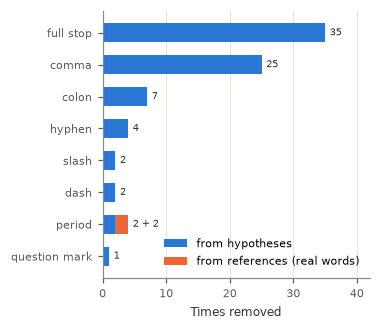

In [11]:
# Figure for the report: which spoken punctuation terms were removed
used = terms[terms["removed from hypotheses"] + terms["removed from references"] > 0]
with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=(3.5, 0.28 * len(used) + 0.8))
    y = np.arange(len(used))[::-1]
    ax.barh(y, used["removed from hypotheses"], color=BLUE, height=0.6, label="from hypotheses")
    ax.barh(y, used["removed from references"], left=used["removed from hypotheses"], color=ORANGE, height=0.6,
            label="from references (real words)")
    for yi, (h, r) in zip(y, zip(used["removed from hypotheses"], used["removed from references"])):
        ax.annotate(f"{h}" + (f" + {r}" if r else ""), (h + r, yi), xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=6.5, color=INK)
    ax.set_yticks(y, used.index)
    ax.set_xlabel("Times removed")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, (used["removed from hypotheses"] + used["removed from references"]).max() * 1.2)
    ax.legend(loc="lower right")
    plt.tight_layout()
    save_report_figure(fig, "punctuation_terms_removed")
    plt.show()

### 4.1 Terms removed from references (probably real words)

In [12]:
ref_hits = d[d["terms_ref"].str.len() > 0]
if len(ref_hits) == 0:
    print("No terms were removed from any reference.")
else:
    show = ref_hits[["sample_id", "terms_ref", "wer_kept", "wer_removed", "reference_norm_kept", "hypothesis_norm_kept"]]
    if "reference_transcript" in ref_hits:
        show = show.assign(original_reference=ref_hits["reference_transcript"])
    display(show)

,sample_id,terms_ref,wer_kept,wer_removed,reference_norm_kept,hypothesis_norm_kept,original_reference
18,afrispeech_95fa8e2c87066c1af0f44e735ee21a99,[period],0.2069,0.2143,may almighty allah make it easy for us to observe good deeds at this period of the 1st 10 days of dhul hijjah and grant us the benefits ...,may almighty allah make it easy for us to observe good deeds at this period of the 1st 10 days of jil high fun hijah and grant us the be...,May Almighty Allah make it easy for us to observe good deeds at this period of the first 10 days of Dhul-Hijjah and grant us the benefit...
146,afrispeech_b3c2ead770875cc7d6cbe2a387fc2b28,[period],0.6471,0.6667,for instance james segars from the department of gynecology and obstetrics at johns hopkins university in baltimore md told the atlantic...,for instance koma james sheger is koma from the department of ganonology and of structural sciences at johns high school university in b...,"For instance, James Segars, from the department of gynecology and obstetrics at Johns Hopkins University in Baltimore, MD, told The Atla..."


**Analysis of terms removed:** 

From the hypotheses, **78 punctuation terms (114 words) were removed in 49 of the 171 recordings**:

* full stop: 35 (in 32 recordings)
* comma: 25
* colon: 7
* hyphen: 4
* slash: 2
* dash: 2
* period: 2
* question mark: 1

Eight terms in the list never occurred in this sample: the bracket and parenthesis terms, exclamation mark, semicolon / semi colon, and query. They are harmless but unused.

**Two terms were removed from references, both "period", and both are real words**: *"at this period of the first 10 days"* and *"having a monthly period"*. The references contain punctuation symbols rather than spoken words, so any match in a reference is a real word. In both recordings Whisper also transcribed *period* correctly, and the same word was removed from the hypothesis. "Period" was never used as spoken punctuation anywhere in this sample, so **removing "period" from the list would lose nothing and fix both recordings.** "Colon" carries a similar risk in clinical text (the organ), although it did not occur in any reference here.

## 5. Recordings that got worse

In [13]:
worse = d[d["outcome"] == "worse"]
print(f"{len(worse)} recordings got worse")
for _, r in worse.iterrows():
    print(f"\n{r['sample_id']}  WER {r['wer_kept']:.3f} -> {r['wer_removed']:.3f}   "
          f"(removed from ref: {r['terms_ref']}, from hyp: {r['terms_hyp']})")
    print(f"  ref (kept):    {r['reference_norm_kept']}")
    print(f"  ref (removed): {r['reference_norm_removed']}")
    print(f"  hyp (kept):    {r['hypothesis_norm_kept']}")
    print(f"  hyp (removed): {r['hypothesis_norm_removed']}")

2 recordings got worse

afrispeech_95fa8e2c87066c1af0f44e735ee21a99  WER 0.207 -> 0.214   (removed from ref: ['period'], from hyp: ['period'])
  ref (kept):    may almighty allah make it easy for us to observe good deeds at this period of the 1st 10 days of dhul hijjah and grant us the benefits ameen
  ref (removed): may almighty allah make it easy for us to observe good deeds at this of the 1st 10 days of dhul hijjah and grant us the benefits ameen
  hyp (kept):    may almighty allah make it easy for us to observe good deeds at this period of the 1st 10 days of jil high fun hijah and grant us the benefits and means
  hyp (removed): may almighty allah make it easy for us to observe good deeds at this of the 1st 10 days of jil high fun hijah and grant us the benefits and means

afrispeech_b3c2ead770875cc7d6cbe2a387fc2b28  WER 0.647 -> 0.667   (removed from ref: ['period'], from hyp: ['period'])
  ref (kept):    for instance james segars from the department of gynecology and obstetrics a

**Analysis of recordings that got worse:** 

Only two recordings got worse, both because of "period" (section 4.1): WER 20.7% → 21.4% (+0.7 pp) and 64.7% → 66.7% (+2.0 pp). In each case the removal deleted a word that was spoken and correctly recognised, from both the reference and the hypothesis. The recording lost one correct word, and the WER rose slightly because the reference became one word shorter. The effect is tiny, but it is a systematic risk of removing words that can also be ordinary English, and it could be fixed by dropping "period" from the list.

## 6. Largest changes

In [14]:
N_SHOW = 8
largest = d.reindex(d["wer_change"].abs().sort_values(ascending=False).index).head(N_SHOW)
display(largest[["sample_id", "accent", "domain", "n_reference_words_kept", "wer_kept", "wer_removed",
                 "wer_change", "terms_hyp"]].round(3))
for _, r in largest.head(3).iterrows():
    print(f"\n{r['sample_id']}  WER {r['wer_kept']:.3f} -> {r['wer_removed']:.3f}")
    print(f"  ref:           {r['reference_norm_removed']}")
    print(f"  hyp (kept):    {r['hypothesis_norm_kept']}")
    print(f"  hyp (removed): {r['hypothesis_norm_removed']}")

big = d["wer_change"].abs() >= 0.10
print(f"\nRecordings whose WER changed by 10 pp or more: {big.sum()} "
      f"(all short clips? median reference length {d.loc[big, 'n_reference_words_kept'].median():.0f} words "
      f"vs {d['n_reference_words_kept'].median():.0f} overall)")

,sample_id,accent,domain,n_reference_words_kept,wer_kept,wer_removed,wer_change,terms_hyp
133,afrispeech_7bc5376c299b0a6ca6e2c7f22706294d,yoruba,general,5,0.800,0.400,-0.400,[full stop]
0,afrispeech_04d6f887f89b3f49d3f056f073278f51,hausa,clinical,8,0.750,0.500,-0.250,"[hyphen, hyphen]"
30,afrispeech_0f2b80cedc4d707e65fcc98db5c1e60d,kiswahili,general,33,0.303,0.061,-0.242,"[full stop, full stop, full stop, full stop]"
15,afrispeech_79ac5eb468c1843701b15908a0f99ede,hausa,general,29,0.552,0.310,-0.241,"[comma, dash, dash, comma, comma, comma, comma]"
155,afrispeech_caac26139ae4ffe29379b8c25ed24e7c,yoruba,general,17,0.588,0.353,-0.235,"[comma, comma, full stop]"
32,afrispeech_1ee383dcfb92b50177e00fbc3f21be05,kiswahili,general,9,0.778,0.556,-0.222,"[colon, comma]"
99,afrispeech_2ca937555c2e6f816415f99842cab781,yoruba,clinical,23,0.217,0.000,-0.217,"[comma, comma, comma, full stop]"
45,afrispeech_61338f7684a6fd6a6d8cde9141580949,kiswahili,general,19,0.421,0.211,-0.211,"[comma, comma, full stop]"



afrispeech_7bc5376c299b0a6ca6e2c7f22706294d  WER 0.800 -> 0.400
  ref:           track listing adapted from allmusic
  hyp (kept):    track listing adapted from all music full stop
  hyp (removed): track listing adapted from all music

afrispeech_04d6f887f89b3f49d3f056f073278f51  WER 0.750 -> 0.500
  ref:           resp vent change fio 2 40% f 4
  hyp (kept):    respiration hyphen ventilation change hyphen fio 240% f 4
  hyp (removed): respiration ventilation change fio 240% f 4

afrispeech_0f2b80cedc4d707e65fcc98db5c1e60d  WER 0.303 -> 0.061
  ref:           abdominal fullness with abdominal pain next line babalade lotachi ogaminana no history of use of blood thinners no history of blood disorders in the family she does not bleed from any other orifice
  hyp (kept):    abdominal fullness with abdominal pain full stop next line full stop babalade lothachi ogaminana no history of use of blood thinners full stop no history of blood disorders in the family full stop she does not breed fr

**Analysis of largest changes:** 

The largest improvements come from short clips or clips with many spoken punctuation marks:

* A 5-word clip (*"track listing adapted from allmusic"* + "full stop") went from 80% to 40% WER from a single removed term.
* A 33-word clinical note with four "full stop"s went from 30.3% to 6.1%.
* A 29-word clip with seven commas and dashes went from 55.2% to 31.0%.
* A 23-word clip went from 21.7% to 0%. Whisper had transcribed it perfectly apart from the spoken punctuation.

26 recordings changed by 10 pp or more. For these recordings, uncorrected spoken punctuation would have dominated the WER, which shows why the correction is needed before comparing accents.

## 7. Spoken punctuation that Whisper mis-recognised

The removal only works if Whisper writes the punctuation word correctly. If it hears "comma" as *coma* or
"full stop" as *full stock*, the word is not in the list and still counts as an error. Nothing is done about these
in the scoring (adding real words such as *coma* or *stop* to the list would also delete them where they were
actually spoken), but it is useful to know how much error they still contribute.

**Step 1:** the most common words Whisper **inserted** (after removal). Spoken punctuation that slipped through
shows up here, because the references contain no punctuation words.

In [15]:
ins_counter = Counter(w for ws in d["ins_words_removed"] for w in ws)
sub_counter = Counter(h for ps in d["sub_pairs_removed"] for _, h in ps)
top = pd.DataFrame({"inserted": pd.Series(ins_counter), "as substitution": pd.Series(sub_counter)}).fillna(0).astype(int)
top["total"] = top.sum(axis=1)
top["recordings"] = pd.Series({w: int(sum(w in set(ws) for ws in d["ins_words_removed"]) +
                                     sum(w in {h for _, h in ps} for ps in d["sub_pairs_removed"])) for w in top.index})
print("Most common inserted words after removal (and how often the same word appears as a substitution):")
display(top.sort_values("inserted", ascending=False).head(25))

Most common inserted words after removal (and how often the same word appears as a substitution):


,inserted,as substitution,total,recordings
coma,23,7,30,23
i,23,8,31,23
of,20,14,34,33
1st,16,2,18,15
the,15,28,43,35
koma,14,11,25,13
is,11,23,34,34
to,10,9,19,19
a,10,6,16,16
and,10,6,16,14


**Step 2:** count the words in `NEAR_MISS_WORDS` (edit the list in the config after looking at step 1). Only
occurrences that are errors are counted, so a real *coma* that matches the reference is not included.

In [16]:
near = []
for w in NEAR_MISS_WORDS:
    n_ins = ins_counter.get(w, 0)
    n_sub = sub_counter.get(w, 0)
    in_refs = int(d["reference_norm_removed"].str.split().map(lambda t: w in t).sum())
    near.append({"word": w, "as insertion": n_ins, "as substitution": n_sub, "recordings with it in reference": in_refs})
near = pd.DataFrame(near).set_index("word")
near["total errors"] = near["as insertion"] + near["as substitution"]
display(near.sort_values("total errors", ascending=False))

near_err = int(near["total errors"].sum())
ref_words = int(d["n_reference_words_removed"].sum())
print(f"Errors on these words: {near_err} of {int(d['errors_removed'].sum())} remaining errors "
      f"({near_err / d['errors_removed'].sum():.1%}), i.e. at most {near_err / ref_words * 100:.1f} pp of corpus WER")
has_near = d.apply(lambda r: any(w in NEAR_MISS_WORDS for w in r["ins_words_removed"]) or
                             any(h in NEAR_MISS_WORDS for _, h in r["sub_pairs_removed"]), axis=1)
print(f"Recordings affected: {has_near.sum()} of {len(d)}")
print("(An upper bound: 'full', 'stop', 'store' and 'stock' are also ordinary words.)")

phr = pd.DataFrame([{"phrase": p,
                     "in hypotheses": int(sum(len(find_terms(h, [p.split()])) for h in d["hypothesis_norm_removed"])),
                     "in references": int(sum(len(find_terms(r, [p.split()])) for r in d["reference_norm_removed"]))}
                    for p in NEAR_MISS_PHRASES]).set_index("phrase")
print("Phrases that look like a mis-heard 'full stop':")
display(phr[phr.sum(axis=1) > 0])

,as insertion,as substitution,recordings with it in reference,total errors
word,,,,
coma,23,7,0,30
koma,14,11,0,25
full,9,3,2,12
stock,6,2,2,8
stop,2,4,1,6
stone,2,0,0,2
store,1,1,1,2
fustob,2,0,0,2
stall,1,0,0,1


Errors on these words: 88 of 1392 remaining errors (6.3%), i.e. at most 2.7 pp of corpus WER
Recordings affected: 43 of 171
(An upper bound: 'full', 'stop', 'store' and 'stock' are also ordinary words.)
Phrases that look like a mis-heard 'full stop':


,in hypotheses,in references
phrase,,
full stock,4,0
full stall,1,0
full store,1,0
full stone,2,0
for stop,2,0
to stop,3,0
just stop,1,0
1st up,4,0


**Step 3:** punctuation phrases that are not in the list. `CANDIDATE_TERMS` (e.g. "next line", which is commented
out in `normalize.py`) are counted, and the effect of also removing them is estimated by re-scoring with jiwer.

In [17]:
CAND = sorted([p.split() for p in CANDIDATE_TERMS], key=len, reverse=True)
def strip(text, phrases):
    tokens, kept_tokens, i = text.split(), [], 0
    while i < len(tokens):
        for p in phrases:
            if tokens[i:i + len(p)] == p:
                i += len(p); break
        else:
            kept_tokens.append(tokens[i]); i += 1
    return " ".join(kept_tokens)

rows = []
for term in CANDIDATE_TERMS:
    p = [term.split()]
    rows.append({"term": term,
                 "in hypotheses": int(sum(len(find_terms(h, p)) for h in d["hypothesis_norm_removed"])),
                 "in references": int(sum(len(find_terms(r, p)) for r in d["reference_norm_removed"]))})
display(pd.DataFrame(rows).set_index("term"))

refs = [strip(r, CAND) for r in d["reference_norm_removed"]]
hyps = [strip(h, CAND) for h in d["hypothesis_norm_removed"]]
new = [jiwer.process_words(r, h) for r, h in zip(refs, hyps)]
new_err = sum(o.substitutions + o.deletions + o.insertions for o in new)
new_n = sum(len(r.split()) for r in refs)
print(f"Corpus WER now: {d['errors_removed'].sum() / d['n_reference_words_removed'].sum() * 100:.2f}%  ->  "
      f"also removing {CANDIDATE_TERMS}: {new_err / new_n * 100:.2f}%")

,in hypotheses,in references
term,,
next line,3,3
new line,0,0


Corpus WER now: 42.53%  ->  also removing ['next line', 'new line']: 42.61%


**Analysis of mis-recognised punctuation:** 

The removal only catches punctuation words that Whisper spelled correctly, and some slipped through.

* **"Comma" heard as *coma* or *koma*** is by far the most common: 30 and 25 errors respectively, in 23 and 13 recordings. Neither word appears in any reference, so these are almost certainly spoken commas.
* **"Full stop" heard as something else** appears as *full stock* (4), *1st up* (4), *to stop* (3), *for stop* (2), and single words such as *stock*, *stone*, *store* and *fustob*.

Together the listed near-miss words account for **88 of the 1392 remaining errors (6.3%)**, in 43 of the 171 recordings. That is **at most 2.7 pp of corpus WER**. It is an upper bound, because *full*, *stop*, *store* and *stock* are also ordinary words.

These are deliberately **not** removed. Adding *coma* (a real clinical term) or *stop* to the list would delete genuine words, the same problem as "period" in section 4. The remaining AfriSpeech WER is therefore slightly inflated by mis-heard punctuation; this should be stated as a limitation.

**"Next line"** (commented out in `normalize.py`) should **not** be added. It occurs 3 times in the hypotheses but also 3 times in the references, because two dictated clinical notes contain "next line" written as words. Removing it would raise corpus WER slightly (42.53% → 42.61%).

## 8. Summary

**Summary.** AfriSpeech speakers were asked to say punctuation aloud, but the reference transcripts contain punctuation symbols. Without correction, Whisper's correct transcription of the spoken words was counted as inserted errors.

Removing a fixed list of spoken-punctuation phrases (whole-word matches only) from both reference and hypothesis lowered AfriSpeech **corpus WER from 45.9% to 42.5%** and mean WER from 49.8% to 46.4%. Almost all of this came from **18% fewer insertions** (584 → 477). SAA was unaffected.

* **Consistent:** of the 48 recordings that changed, 46 improved, with a median improvement of 10.3 pp.
* **Mostly full stops and commas:** 78 terms were removed from the hypotheses, mainly "full stop" (35) and "comma" (25).
* **Differs by accent:** the effect was −5.2 pp for Kiswahili, −4.6 pp for Hausa and −2.4 pp for Yoruba. Without the correction, accent comparisons would partly reflect how often speakers followed the punctuation instruction, although the accent ordering is the same either way.

The only side effect is the word "period": it was removed twice from references where it was a real word, making two recordings slightly worse (+0.7 and +2.0 pp). It was never used as spoken punctuation in this sample and can safely be dropped from the list.

Mis-recognised punctuation (mainly "comma" heard as *coma*/*koma*) still contributes up to 2.7 pp of corpus WER. It is left in, because removing real words such as *coma* would cause the same problem as "period".